<a href="https://colab.research.google.com/github/7mid056/Heart-Disease-predictor/blob/main/Heart_Disease_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
from tqdm import tqdm

path = kagglehub.dataset_download("yasserh/heart-disease-dataset")

print("Path to dataset files:",path)

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.
Path to dataset files: /kaggle/input/heart-disease-dataset


In [48]:
csv_path = os.path.join(path,"heart.csv")

df = pd.read_csv(csv_path)
(df['target']== 0).sum()

np.int64(138)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [50]:
def check_duplicates(df):
  duplicates = df.duplicated().sum()
  print(f"Number of Duplicate Samples: {duplicates}")
  if duplicates > 0:
    print("Dropping Duplicates...")
    df.drop_duplicates(inplace=True)
    print("Duplicates Dropped.")
  else:
    print("No Duplicate Samples Found.")
check_duplicates(df)
df.info()

Number of Duplicate Samples: 1
Dropping Duplicates...
Duplicates Dropped.
<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


target
1    0.543046
0    0.456954
Name: proportion, dtype: float64


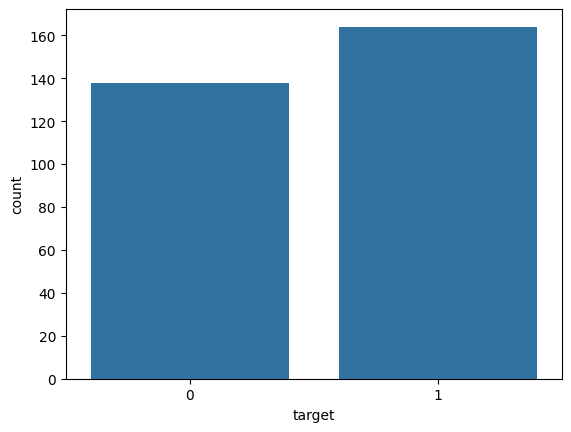

In [51]:
def check_target_imbalance(df,target_column):
  print(df[target_column].value_counts(normalize = True))
  sns.countplot(x=df[target_column])
  plt.show
check_target_imbalance(df,"target")

In [52]:
# 2. Do we have missing values?
def check_missing_values(df):
  missing_values = df.isnull().sum()
  print("Missing Values per Column:")
  print(missing_values[missing_values > 0])
  if missing_values.any():
    print("\nHandle Missing Values as needed.")
  else:
    print("\nNo Missing Values Found.")
check_missing_values(df)

Missing Values per Column:
Series([], dtype: int64)

No Missing Values Found.


In [53]:
from sklearn.preprocessing import StandardScaler

numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop("target")  # DON'T SCALE THE TARGET

scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0.949794,0.682656,1.976470,0.764066,-0.261285,2.389793,-1.002541,0.018826,-0.698344,1.084022,-2.271182,-0.714911,-2.147955,1
1,-1.928548,0.682656,1.005911,-0.091401,0.067741,-0.418446,0.901657,1.636979,-0.698344,2.118926,-2.271182,-0.714911,-0.513994,1
2,-1.485726,-1.464866,0.035352,-0.091401,-0.822564,-0.418446,-1.002541,0.980971,-0.698344,0.307844,0.979514,-0.714911,-0.513994,1
3,0.174856,0.682656,0.035352,-0.661712,-0.203222,-0.418446,0.901657,1.243374,-0.698344,-0.209608,0.979514,-0.714911,-0.513994,1
4,0.285561,-1.464866,-0.935208,-0.661712,2.080602,-0.418446,0.901657,0.587366,1.431958,-0.382092,0.979514,-0.714911,-0.513994,1


In [54]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1).astype(float)
y = df['target'].astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [55]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))


# BCE in NumPy
def binary_cross_entropy(y, y_hat):
  epsilon = 1e-15  # Very small number to prevent log(0)
  y_hat = np.clip(y_hat, epsilon, 1 - epsilon) # np.clip(value, min, max)

  loss = -1/len(y) * np.sum(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
  return loss

In [56]:
def gradient_descent(X, y, learning_rate, n_iters=500):
  m, n = X.shape # m rows, n columns (dimensions)
  theta = np.zeros(n) # initialize a zeros weight vector with n dimensions
  losses = []

  for _ in tqdm(range(n_iters), desc="Training Logistic Regression"):
    z = np.dot(X, theta)
    y_hat = sigmoid(z)
    gradient = np.dot(X.T, (y_hat - y)) / m
    theta -= learning_rate * gradient

    loss = binary_cross_entropy(y, y_hat)
    losses.append(loss)

  return theta, losses

In [58]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


n_splits = 5 # K=5 Folds

# Stratified 5-Fold Cross-Validation, shuffled
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)


# Storage for logistic regression results for each fold
lr_losses = []
lr_accuracy = []
lr_precision = []
lr_recall = []
lr_f1 = []


for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train, y_train)):
    print(f"\nFold {fold_idx + 1}/{n_splits}")

    X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

    # Train
    theta, losses = gradient_descent(X_fold_train, y_fold_train, learning_rate=0.3, n_iters=200)

    # Validate
    y_pred_proba = sigmoid(np.dot(X_fold_val, theta))
    y_pred = (y_pred_proba >= 0.3).astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_fold_val, y_pred)
    precision = precision_score(y_fold_val, y_pred, zero_division=0)
    recall = recall_score(y_fold_val, y_pred, zero_division=0)
    f1 = f1_score(y_fold_val, y_pred, zero_division=0)

    # Store results
    lr_losses.append(losses)
    lr_accuracy.append(accuracy)
    lr_precision.append(precision)
    lr_recall.append(recall)
    lr_f1.append(f1)


Fold 1/5


Training Logistic Regression: 100%|██████████| 200/200 [00:00<00:00, 797.32it/s]



Fold 2/5


Training Logistic Regression: 100%|██████████| 200/200 [00:00<00:00, 712.70it/s]



Fold 3/5


Training Logistic Regression: 100%|██████████| 200/200 [00:00<00:00, 1317.33it/s]



Fold 4/5


Training Logistic Regression: 100%|██████████| 200/200 [00:00<00:00, 1283.27it/s]



Fold 5/5


Training Logistic Regression: 100%|██████████| 200/200 [00:00<00:00, 1370.67it/s]


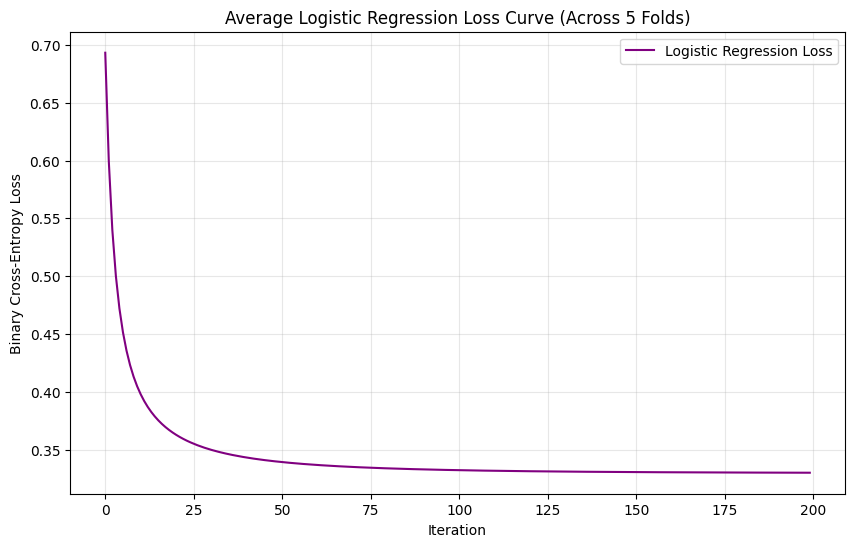

In [59]:
avg_loss = np.mean(lr_losses, axis=0)

plt.figure(figsize=(10, 6))
plt.plot(avg_loss, label='Logistic Regression Loss', color='purple')
plt.title('Average Logistic Regression Loss Curve (Across 5 Folds)')
plt.xlabel('Iteration')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [61]:
print("LOGISTIC REGRESSION Performance:")
print(f"  Accuracy:  {np.mean(lr_accuracy):.4f}")
print(f"  Precision: {np.mean(lr_precision):.4f}")
print(f"  Recall:    {np.mean(lr_recall):.4f}")
print(f"  F1-Score:  {np.mean(lr_f1):.4f}")


LOGISTIC REGRESSION Performance:
  Accuracy:  0.8340
  Precision: 0.7984
  Recall:    0.9387
  F1-Score:  0.8614


theta is the most important thing in the entire model its the لب الموضوع كله

In [72]:


y_hat_test = sigmoid(np.dot(X_test, theta))
y_pred_test = (y_hat_test >= 0.3).astype(int)    # introvert -------> 1
                                                 # if the negative is important i must decrease the threshold
print("\nFinal Test Results")
print(f"Accuracy: {(accuracy_score(y_test, y_pred_test))*100:.2f}%")
print(f"Precision: {(precision_score(y_test, y_pred_test, zero_division=0))*100:.2f}%")
print(f"Recall: {(recall_score(y_test, y_pred_test, zero_division=0))*100:.2f}%")
print(f"F1 Score: {(f1_score(y_test, y_pred_test, zero_division=0))*100:.2f}%")



Final Test Results
Accuracy: 80.33%
Precision: 75.61%
Recall: 93.94%
F1 Score: 83.78%
